Today's topics:

* formation energy against composition
* the lower convex hull
* `energy_above_hull` and `is_stable`
* building the hull with lists and a loop
* phase diagrams with pymatgen

# Titanium oxides

Today we will find which titanium oxides are stable.

Titanium dioxide, TiO$_2$, is the white pigment in paint, paper, and sunscreen.
It has two common crystal forms.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/3/3f/Rutile-114264.jpg/960px-Rutile-114264.jpg" alt="A dark, shiny, blocky rutile crystal on a rock" width="300"/>
<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/7/75/Anatase_%28several_crystals%29_-_Datas_%28Dattas%29%2C_Minas_Gerais%2C_Brazil.jpg/960px-Anatase_%28several_crystals%29_-_Datas_%28Dattas%29%2C_Minas_Gerais%2C_Brazil.jpg" alt="Ten brown pointed anatase crystals in two rows" width="480"/>

*Left: rutile, photo by Robert M. Lavinsky, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Rutile-114264.jpg). Right: anatase crystals from Minas Gerais, Brazil, photo by Kelly Nash, [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Anatase_(several_crystals)_-_Datas_(Dattas),_Minas_Gerais,_Brazil.jpg).*

Above: rutile (left) and anatase (right), two crystal forms of TiO$_2$.

Which one is the stable form of TiO$_2$?
What other titanium oxides are there?

## Setup

Colab starts a fresh computer each session.
Let's install `mp-api` again.

> ⏳ This could take a few minutes.

In [1]:
!pip install mp-api==0.47.0

In [2]:
#@title Read your Materials Project key (click ▶ to run) { display-mode: "form" }
try:
    from google.colab import userdata
    API_KEY = userdata.get('MaterialsProject')
except ImportError:
    import os
    API_KEY = os.environ['MP_API_KEY']

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from mp_api.client import MPRester

# Formation energy against composition

## Every titanium oxide

Let's search for every Ti-O entry.
That includes the unstable ones.

Three fields are new: `energy_above_hull`, `is_stable`, and `theoretical`.

In [4]:
with MPRester(API_KEY) as mpr:
    ti_o_docs = mpr.materials.summary.search(
        chemsys='Ti-O',  # no is_stable filter: we want every entry
        fields=['material_id', 'formula_pretty', 'composition',
                'formation_energy_per_atom', 'energy_above_hull',
                'is_stable', 'theoretical'],
    )

print(len(ti_o_docs))

✓ Retrieved 124 SummaryDoc documents in 0.9s

124


Let's build the table with the same loop as in Lecture 30:

In [5]:
records = []
for doc in ti_o_docs:
    records.append({
        'material_id': str(doc.material_id),
        'formula_pretty': doc.formula_pretty,
        'x_O': doc.composition.get_atomic_fraction('O'),
        'formation_energy_per_atom': doc.formation_energy_per_atom,
        'energy_above_hull': doc.energy_above_hull,
        'is_stable': doc.is_stable,
        'theoretical': doc.theoretical,
    })

ti_o = pd.DataFrame(records)
display(ti_o)

,material_id,formula_pretty,x_O,formation_energy_per_atom,energy_above_hull,is_stable,theoretical
0,mp-684733,Ti10O11,0.523810,-2.856115,0.146003,False,True
1,mp-753593,Ti10O13,0.565217,-3.137637,0.028243,False,True
2,mp-759754,Ti11O14,0.560000,-3.098234,0.047013,False,True
3,mp-1101463,Ti11O14,0.560000,-3.097261,0.047985,False,True
4,mp-2739250,Ti11O14,0.560000,-2.952311,0.058592,False,True
...,...,...,...,...,...,...,...
119,mp-1426806,TiO2,0.666667,-3.349836,0.158219,False,True
120,mp-1445035,TiO2,0.666667,-0.763507,2.744549,False,True
121,mp-2420244,TiO2,0.666667,-3.491561,0.016494,False,True
122,mp-2739239,TiO2,0.666667,-3.416520,0.091535,False,True


One row per crystal structure.
`x_O` is the atomic fraction of oxygen.
TiO$_2$ has $x_O = 2/3$.

Let's plot formation energy against `x_O`.
Hover to read the formulas:

In [6]:
px.scatter(ti_o, x='x_O', y='formation_energy_per_atom', hover_name='formula_pretty')

Every entry is below zero.
Each one releases energy when it forms from pure Ti and pure O.

The lowest points are near $x_O = 2/3$, which is TiO$_2$.

## The pure elements

The search returned no entries at $x_O = 0$ or $x_O = 1$:

In [7]:
print(ti_o['x_O'].min())
print(ti_o['x_O'].max())

0.14285714285714285
0.7777777777777778


Pure Ti and pure O are not in a Ti-O search.

Formation energy is measured from the pure elements.
So both have exactly 0 eV/atom.

They are the two end points of the plot: $(0, 0)$ and $(1, 0)$.

# The lower convex hull

## What is the hull?

Picture the plot of every entry.
A mix of two compounds has an energy on the straight line between their points.

If an entry lies above that line, it can lower its energy by splitting into the two compounds.
That entry is not stable.

The stable entries are the ones on the **lower convex hull**, the lowest boundary of the points.
The **energy above the hull** is how far an entry sits above that boundary.

## Energy above the hull

Two of the new fields measure stability.
`energy_above_hull` is a number in eV/atom.
`is_stable` is `True` or `False`.

Let's keep the entries whose energy above the hull is exactly 0:

In [8]:
stable = ti_o[ti_o['energy_above_hull'] == 0]
display(stable)

,material_id,formula_pretty,x_O,formation_energy_per_atom,energy_above_hull,is_stable,theoretical
8,mp-1215,Ti2O,0.333333,-2.035562,0.0,True,False
15,mp-458,Ti2O3,0.600000,-3.303440,0.0,True,False
23,mp-2591,Ti3O,0.250000,-1.569914,0.0,True,False
33,mp-8057,Ti3O5,0.625000,-3.382134,0.0,True,False
53,mp-554098,Ti6O,0.142857,-0.916695,0.0,True,False
72,mp-1071163,TiO,0.500000,-2.907956,0.0,True,False
78,mp-390,TiO2,0.666667,-3.508055,0.0,True,False


Seven entries.
Each one is a different compound.

In [9]:
print(len(stable))
print(ti_o['is_stable'].sum())  # True counts as 1

7
7


`is_stable` is `True` for the same seven.
Stable means an energy above the hull of 0.

## Building the lower hull

Let's sort the stable entries by `x_O`.
Sorting puts the points in left-to-right order.

`sort_values` returns a sorted copy:

In [10]:
stable = stable.sort_values(by='x_O')
display(stable)

,material_id,formula_pretty,x_O,formation_energy_per_atom,energy_above_hull,is_stable,theoretical
53,mp-554098,Ti6O,0.142857,-0.916695,0.0,True,False
23,mp-2591,Ti3O,0.250000,-1.569914,0.0,True,False
8,mp-1215,Ti2O,0.333333,-2.035562,0.0,True,False
72,mp-1071163,TiO,0.500000,-2.907956,0.0,True,False
15,mp-458,Ti2O3,0.600000,-3.303440,0.0,True,False
33,mp-8057,Ti3O5,0.625000,-3.382134,0.0,True,False
78,mp-390,TiO2,0.666667,-3.508055,0.0,True,False


We use two lists to plot the hull.
`hull_x` holds the compositions.
`hull_e` holds the energies.

Pure Ti goes first.
A loop adds the stable entries one at a time.
Pure O goes last.

`zip` walks two columns together.
Each pass gives the composition and the energy from the same row.

In [11]:
hull_x = [0]  # pure Ti: x_O = 0
hull_e = [0]  # and its formation energy, 0

for x, energy in zip(stable['x_O'], stable['formation_energy_per_atom']):  # zip pairs each x_O with the energy in its row
    hull_x.append(x)
    hull_e.append(energy)

hull_x.append(1)  # pure O: x_O = 1
hull_e.append(0)

print(hull_x)
print(hull_e)

[0, 0.14285714285714285, 0.25, 0.3333333333333333, 0.5, 0.6, 0.625, 0.6666666666666666, 1]
[0, -0.9166954207142847, -1.5699139624999994, -2.035562333888889, -2.9079562791666667, -3.3034396343333343, -3.382133738125, -3.5080554519444447, 0]


Let's draw the hull over all the entries:

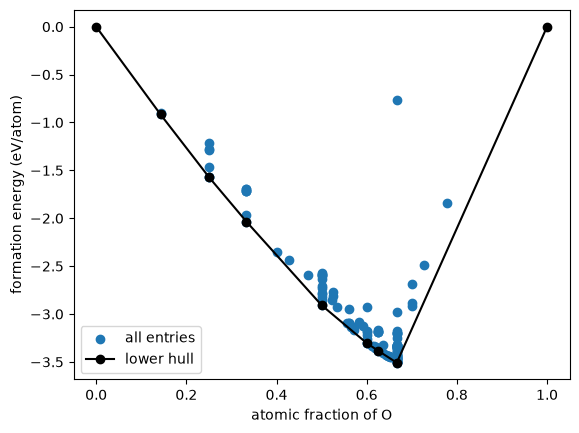

In [12]:
fig, ax = plt.subplots()
ax.scatter(ti_o['x_O'], ti_o['formation_energy_per_atom'], label='all entries')
ax.plot(hull_x, hull_e, 'k-o', label='lower hull')
ax.set_xlabel('atomic fraction of O')
ax.set_ylabel('formation energy (eV/atom)')
ax.legend()

No point lies below the line.
The hull bends at each stable compound, from Ti$_6$O on the left to TiO$_2$ on the right.

The one point far above it at $x_O = 2/3$ is a TiO$_2$ structure with a high energy.

### [Check your understanding]

Manganese oxides are battery and pigment materials.
The collapsed cell below fetches every Mn-O entry and builds the DataFrame `mn_o`.
It has the same columns as `ti_o`.
Run it.
Then do the hull yourself (about 9 minutes).

1. Select the stable rows of `mn_o` and sort them by `x_O`.
   * Print their formulas.
2. Build `hull_x` and `hull_e` with pure Mn first and pure O last.
3. Plot all the entries with the hull line over them.

Which Mn-O compounds are on the hull?

In [13]:
#@title Load the Mn-O table (same steps as Ti-O) { display-mode: "form" }
with MPRester(API_KEY) as mpr:
    mn_o_docs = mpr.materials.summary.search(
        chemsys='Mn-O',
        fields=['material_id', 'formula_pretty', 'composition',
                'formation_energy_per_atom', 'energy_above_hull',
                'is_stable', 'theoretical'],
    )

records = []
for doc in mn_o_docs:
    records.append({
        'material_id': str(doc.material_id),
        'formula_pretty': doc.formula_pretty,
        'x_O': doc.composition.get_atomic_fraction('O'),
        'formation_energy_per_atom': doc.formation_energy_per_atom,
        'energy_above_hull': doc.energy_above_hull,
        'is_stable': doc.is_stable,
        'theoretical': doc.theoretical,
    })
mn_o = pd.DataFrame(records)

✓ Retrieved 67 SummaryDoc documents in 1.0s

## Compare with a worked version

36      MnO
20    Mn3O4
11    Mn2O3
48     MnO2
Name: formula_pretty, dtype: str


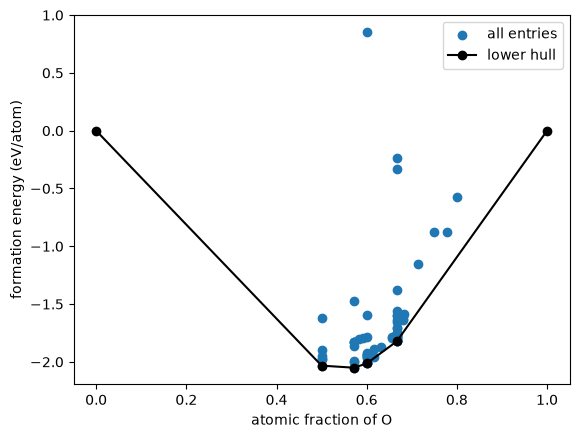

In [14]:
mn_stable = mn_o[mn_o['energy_above_hull'] == 0]
mn_stable = mn_stable.sort_values(by='x_O')
print(mn_stable['formula_pretty'])

mn_hull_x = [0]  # pure Mn
mn_hull_e = [0]
for x, energy in zip(mn_stable['x_O'], mn_stable['formation_energy_per_atom']):
    mn_hull_x.append(x)
    mn_hull_e.append(energy)
mn_hull_x.append(1)  # pure O
mn_hull_e.append(0)

fig, ax = plt.subplots()
ax.scatter(mn_o['x_O'], mn_o['formation_energy_per_atom'], label='all entries')
ax.plot(mn_hull_x, mn_hull_e, 'k-o', label='lower hull')
ax.set_xlabel('atomic fraction of O')
ax.set_ylabel('formation energy (eV/atom)')
ax.legend()

Four compounds are on the hull: MnO, Mn$_3$O$_4$, Mn$_2$O$_3$, and MnO$_2$.
Its lowest point, Mn$_3$O$_4$ at -2.05 eV/atom, is much shallower than TiO$_2$ at -3.51 eV/atom.

# Reading the energy above the hull

## An entry between two hull compounds

Let's zoom in near TiO$_2$.

The column of points at $x_O = 2/3$ is TiO$_2$ in many crystal structures.

Several other points sit just above the hull line between Ti$_3$O$_5$ and TiO$_2$:

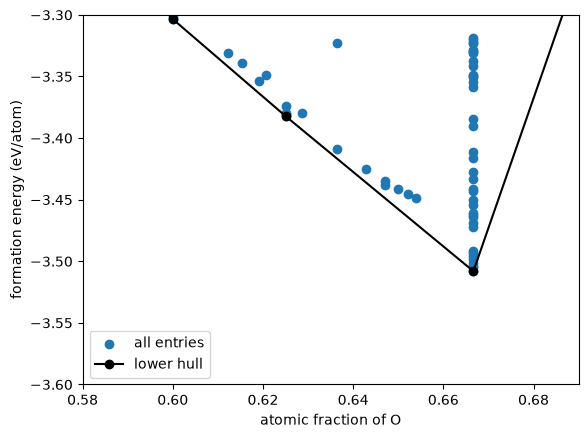

In [15]:
fig, ax = plt.subplots()
ax.scatter(ti_o['x_O'], ti_o['formation_energy_per_atom'], label='all entries')
ax.plot(hull_x, hull_e, 'k-o', label='lower hull')
ax.set_xlim(0.58, 0.69)  # zoom in on Ti3O5 to TiO2
ax.set_ylim(-3.6, -3.3)
ax.set_xlabel('atomic fraction of O')
ax.set_ylabel('formation energy (eV/atom)')
ax.legend()

Let's check one of them, Ti$_4$O$_7$, against the line:

In [16]:
ti_o[ti_o['formula_pretty'] == 'Ti4O7']

,material_id,formula_pretty,x_O,formation_energy_per_atom,energy_above_hull,is_stable,theoretical
47,mp-12205,Ti4O7,0.636364,-3.408519,0.007957,False,False
48,mp-778663,Ti4O7,0.636364,-3.322616,0.093860,False,True


Two Ti$_4$O$_7$ structures: the first has `theoretical` set to `False`.
Materials Project matched its structure to a crystal reported in the ICSD.
The second has no match.
The energies are calculated for both.

The first has an `energy_above_hull` of 0.008 eV/atom.
Let's get that number ourselves from the two hull compounds on either side.

Ti$_3$O$_5$ has 5 of 8 atoms O.
Ti$_4$O$_7$ has 7 of 11.

In [17]:
x_left, e_left = 5/8, -3.3821     # Ti3O5, on the hull
x_right, e_right = 2/3, -3.5081   # TiO2, on the hull
x_mid, e_mid = 7/11, -3.4085      # Ti4O7, the entry to test

share = (x_mid - x_left) / (x_right - x_left)  # fraction of the way from Ti3O5 to TiO2
e_line = e_left + share * (e_right - e_left)   # the line's energy at x_mid
print(e_line)
print(e_mid - e_line)

-3.4164636363636363
0.007963636363636173


The line sits 0.008 eV/atom below Ti$_4$O$_7$.
That matches `energy_above_hull`.

At 0 K, the model predicts a lower-energy mixture of Ti$_3$O$_5$ and TiO$_2$ with the same composition.
Yet Ti$_4$O$_7$ is observed.
It is a Magnéli phase, a titanium oxide that lies between Ti$_3$O$_5$ and TiO$_2$.

## Two forms of titanium dioxide

Back to the opening question.

Let's keep every TiO$_2$ entry and sort by the energy above the hull:

In [18]:
tio2 = ti_o[ti_o['formula_pretty'] == 'TiO2']
tio2 = tio2.sort_values(by='energy_above_hull')
display(tio2.head(6))

,material_id,formula_pretty,x_O,formation_energy_per_atom,energy_above_hull,is_stable,theoretical
78,mp-390,TiO2,0.666667,-3.508055,0.000000,True,False
81,mp-1840,TiO2,0.666667,-3.505014,0.003041,False,False
80,mp-1439,TiO2,0.666667,-3.503532,0.004524,False,False
88,mp-554278,TiO2,0.666667,-3.501638,0.006417,False,False
82,mp-2657,TiO2,0.666667,-3.498529,0.009526,False,False
97,mp-775938,TiO2,0.666667,-3.495809,0.012247,False,True


Which entries are anatase and rutile?

The `symmetry` field gives the space group.
Let's look up three entries by ID:

In [19]:
with MPRester(API_KEY) as mpr:
    tio2_docs = mpr.materials.summary.search(
        material_ids=['mp-390', 'mp-2657', 'mp-1840'],
        fields=['material_id', 'symmetry', 'energy_above_hull'],
    )

for doc in tio2_docs:
    print(doc.material_id, doc.symmetry.symbol, doc.energy_above_hull)

✓ Retrieved 3 SummaryDoc documents in 0.0s

mp-390 I4_1/amd 0.0
mp-2657 P4_2/mnm 0.009526375000000087
mp-1840 Pbca 0.0030413275000000795


$I4_1/amd$ is anatase (`mp-390`) and $P4_2/mnm$ is rutile (`mp-2657`).
The third, `mp-1840`, is the orthorhombic form brookite.

Materials Project puts **anatase** on the hull.
Rutile sits 0.0095 eV/atom above it.

Experiments show the opposite.
Bulk rutile is the stable form, and anatase turns into rutile when heated.

The calculation uses an approximate method (DFT).
A gap this small depends on the approximate method.
Published calculations show that approximate DFT can reverse the anatase and rutile order
([Zhang et al., 2019](https://doi.org/10.1063/1.5055623)).

Temperature alone does not explain it.
Materials Project warns that a small energy above the hull does not rule out a real material
([glossary of terms](https://docs.materialsproject.org/frequently-asked-questions/glossary-of-terms)).
Ti$_4$O$_7$ is the same story: it sits above the hull and it is observed.

So which titanium oxides are stable?
Seven, the entries on our hull:
Ti$_6$O, Ti$_3$O, Ti$_2$O, TiO, Ti$_2$O$_3$, Ti$_3$O$_5$, and TiO$_2$.

# Phase diagrams with pymatgen

## The Ti-O phase diagram

pymatgen builds the hull and draws it.

`get_entries_in_chemsys` returns the entries with a shared energy reference, pure elements included.

In [20]:
from pymatgen.analysis.phase_diagram import PhaseDiagram, PDPlotter

with MPRester(API_KEY) as mpr:
    ti_o_entries = mpr.get_entries_in_chemsys('Ti-O')

ti_o_diagram = PhaseDiagram(ti_o_entries)
PDPlotter(ti_o_diagram).get_plot()

INFO     Fetching the GGA_GGA+U_R2SCAN phase diagram for O-Ti...

The stable entries match our hull.

## Lithium cobalt oxides

A hull with three elements is a surface, not a line.

Let's try lithium, cobalt, and oxygen, the elements of the LiCoO$_2$ battery cathode:

In [21]:
with MPRester(API_KEY) as mpr:
    li_co_o_entries = mpr.get_entries_in_chemsys('Li-Co-O')

li_co_o_diagram = PhaseDiagram(li_co_o_entries)
PDPlotter(li_co_o_diagram).get_plot()

INFO     Fetching the GGA_GGA+U_R2SCAN phase diagram for Co-Li-O...

Each corner is a pure element.

LiCoO$_2$ is on the hull.
It is the cathode in many phone and laptop batteries.

# Summary

* `energy_above_hull` is 0 for a stable entry, and `is_stable` is `True` for the same entries.
* Formation energy is 0 for the pure elements, so the hull runs from $(0, 0)$ to $(1, 0)$.
* `sort_values(by=...)` and a loop with `zip` and `append` build the lists for the lower hull.
* pymatgen's `PhaseDiagram` and `PDPlotter` build and draw the hull, for two elements or more.

# Quiz 9 warm-up

In Q1 you will:
- say which argument of a `summary.search` call picks the material and which picks the property,
- change a search to return two properties of every stable entry in a chemical system.

In Q2 you will:
- pick a real-world application you are interested in,
- say one thing Materials Project could tell you that would help with it,
- say one thing it could not tell you, because its data are for 0 K.

## Further reading

* Materials Project, [Thermodynamic stability](https://docs.materialsproject.org/methodology/materials-methodology/thermodynamic-stability)
* pymatgen, [Phase diagram module](https://pymatgen.org/pymatgen.analysis.html)
* The Materials Project data used here are shared under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).